# 3D C-Space NDF Visualization (Interactive)
This notebook uses **Plotly** to provide a high-performance interactive 3D visualization of the learned Configuration Space.

In [14]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from skimage import measure
from utils import load_model

%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [15]:
model_path = "output/ndf/model_final.pt"
if not os.path.exists(model_path):
    print(f"Error: {model_path} not found. Please run training first.")
else:
    print(f"Loading model from {model_path}...")
    model = load_model(model_path, device)

Loading model from output/ndf/model_final.pt...


In [16]:
res = 64
ticks = np.linspace(-np.pi, np.pi, res)
q1, q2, q3 = np.meshgrid(ticks, ticks, ticks, indexing='ij')
grid_points = np.stack([q1.ravel(), q2.ravel(), q3.ravel()], axis=1)

print(f"Predicting on {res}^3 grid...")
with torch.no_grad():
    batch_size = 100000
    preds = []
    for i in range(0, len(grid_points), batch_size):
        batch = torch.Tensor(grid_points[i:i+batch_size]).to(device)
        p = model(batch).cpu().numpy()
        preds.append(p)
    Z = np.concatenate(preds).reshape(res, res, res)
print("Done.")

Predicting on 64^3 grid...
Done.


### Interactive 3D Scatter (Plotly)
Use your mouse to rotate (drag), zoom (scroll), and pan.

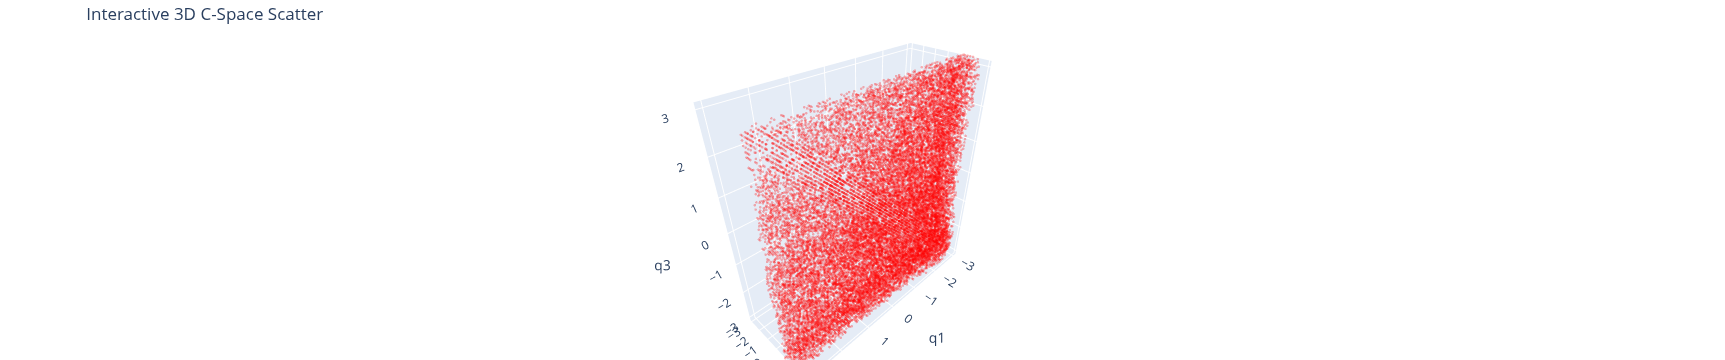

In [17]:
mask = Z < 0
indices = np.where(mask)
max_scatter = 20000
if len(indices[0]) > max_scatter:
    idx = np.random.choice(len(indices[0]), max_scatter, replace=False)
    xs, ys, zs = ticks[indices[0][idx]], ticks[indices[1][idx]], ticks[indices[2][idx]]
else:
    xs, ys, zs = ticks[indices[0]], ticks[indices[1]], ticks[indices[2]]

fig = go.Figure(data=[go.Scatter3d(
    x=xs, y=ys, z=zs,
    mode='markers',
    marker=dict(size=1.5, color='red', opacity=0.3)
)])

fig.update_layout(
    title="Interactive 3D C-Space Scatter",
    scene=dict(
        xaxis_title="q1", yaxis_title="q2", zaxis_title="q3",
        xaxis=dict(range=[-np.pi, np.pi]),
        yaxis=dict(range=[-np.pi, np.pi]),
        zaxis=dict(range=[-np.pi, np.pi])
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)
fig.show()

### Interactive Mesh Rendering (Plotly)
This provides a much smoother 3D rotation experience.

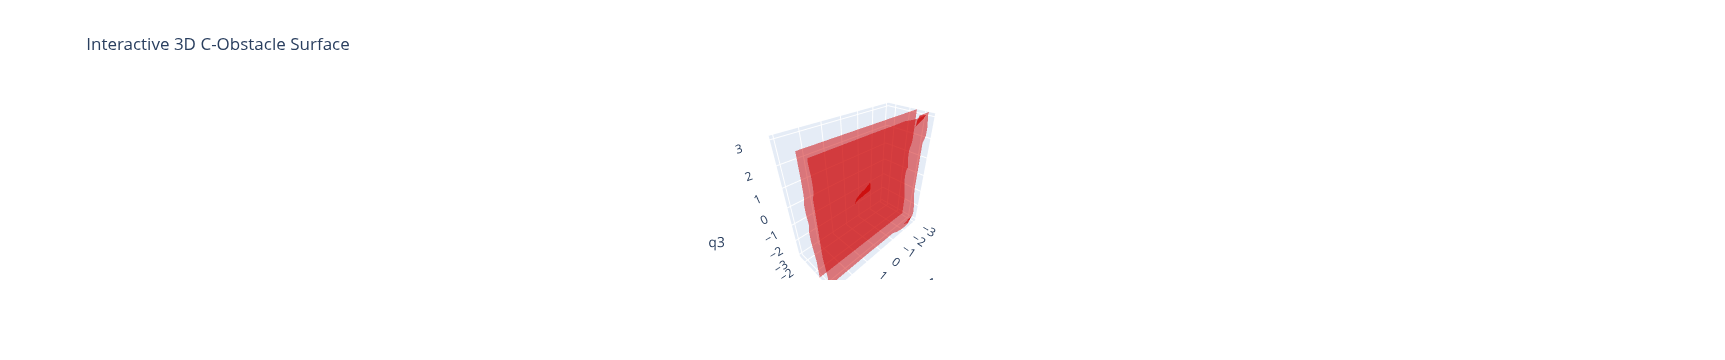

In [18]:
try:
    verts, faces, normals, values = measure.marching_cubes(Z, level=0)
    verts = (verts / (res - 1)) * (2 * np.pi) - np.pi

    fig = go.Figure(data=[go.Mesh3d(
        x=verts[:, 0], y=verts[:, 1], z=verts[:, 2],
        i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
        color='red', opacity=0.5,
        flatshading=True
    )])

    fig.update_layout(
        title="Interactive 3D C-Obstacle Surface",
        scene=dict(
            xaxis_title="q1", yaxis_title="q2", zaxis_title="q3",
            xaxis=dict(range=[-np.pi, np.pi]),
            yaxis=dict(range=[-np.pi, np.pi]),
            zaxis=dict(range=[-np.pi, np.pi])
        )
    )
    fig.show()
except Exception as e:
    print(f"Mesh rendering failed: {e}")

### Static 2D Slices (Matplotlib)

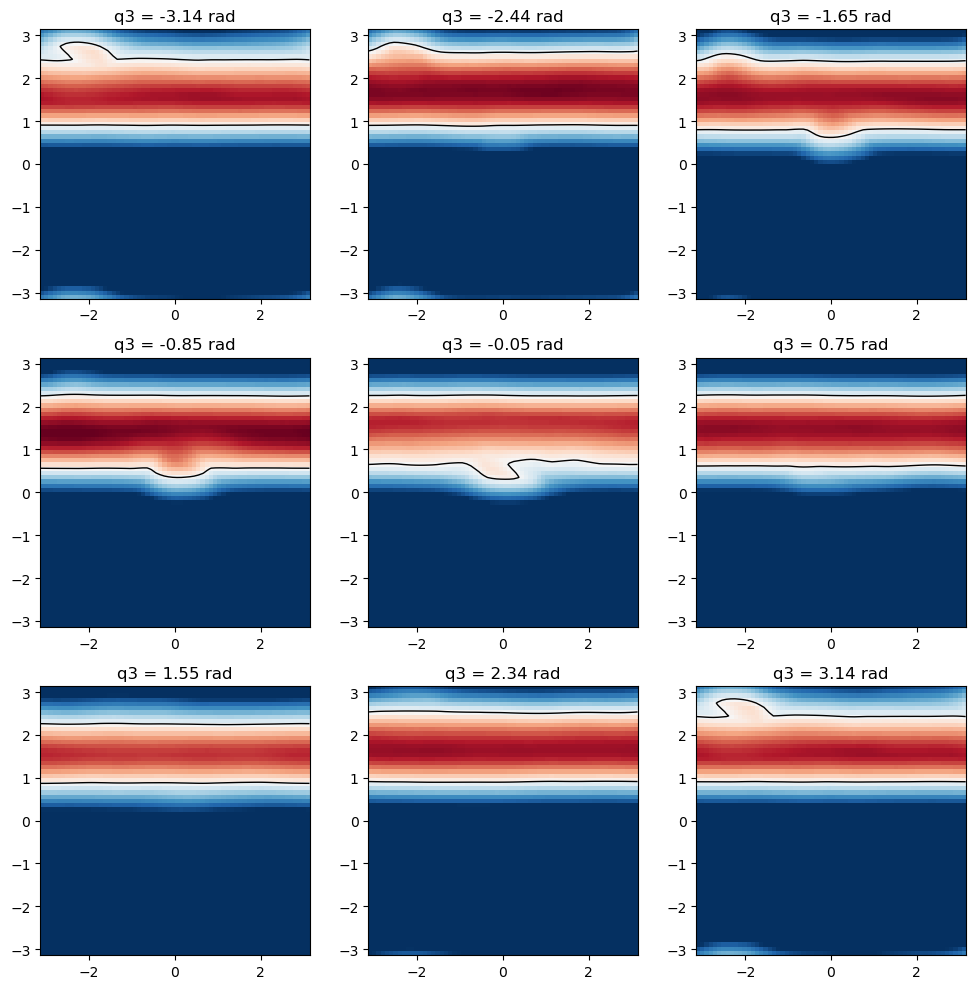

In [19]:
n_slices = 9
slice_indices = np.linspace(0, res-1, n_slices, dtype=int)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.flatten()

for i, idx in enumerate(slice_indices):
    ax = axes[i]
    slice_data = Z[:, :, idx]
    ax.imshow(slice_data.T, origin='lower', extent=[-np.pi, np.pi, -np.pi, np.pi], cmap='RdBu', vmin=-0.5, vmax=0.5)
    ax.contour(ticks, ticks, slice_data.T, levels=[0], colors='black', linewidths=1)
    ax.set_title(f"q3 = {ticks[idx]:.2f} rad")

plt.tight_layout()
plt.show()